<a href="https://colab.research.google.com/github/sejutyanjum/titanic-dataset-analysis/blob/main/Exploratory_Data_Analysis_(EDA)_on_the_Titanic_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Task 1: Data Loading and Initial Inspection

Load the dataset

In [1]:
import pandas as pd

df= pd.read_csv('/content/drive/MyDrive/titanic.csv')

Display the first 5 rows

In [2]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Check the data types of all columns

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Get descriptive statistics of the numerical columns

In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Identify the total number of missing values for each column

In [5]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


#Task 2: Handling Missing Values

Calculate the percentage of missing values in the Cabin column.

In [6]:
df['Cabin'].isnull().mean()*100

np.float64(77.10437710437711)

The Cabin column contains a very high number of missing values. It may not provide reliable insights for the analysis so it should be dropped from the dataset

Find the most frequent port of embarkation (the mode)

In [7]:
df['Embarked'].mode()

,Embarked
0,S


Impute the missing values in the Embarked column with the mode

In [8]:
df['Embarked'].fillna(df['Embarked'].mode()[0],inplace= True)

/tmp/ipykernel_5640/1843428846.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Embarked'].fillna(df['Embarked'].mode()[0],inplace= True)


Impute the missing values in the Age column with the median age

In [9]:
df['Age'].fillna(df['Age'].median(),inplace=True)

/tmp/ipykernel_5640/1527141296.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(),inplace=True)


#Task 3: Univariate Analysis

Calculate the overall survival rate (percentage of passengers who survived)

In [10]:
df['Survived'].mean()*100

np.float64(38.38383838383838)

Visualize the distribution of the Survived variable

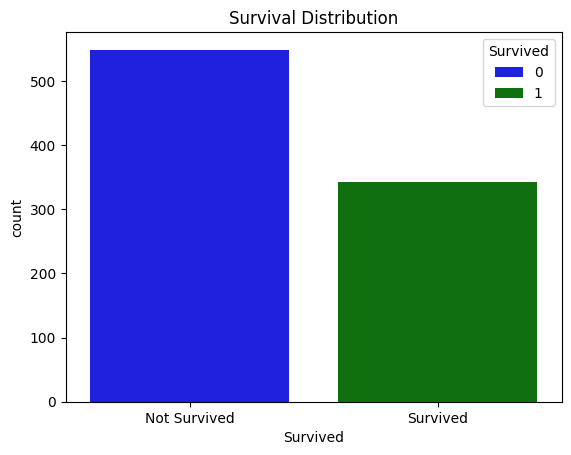

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot class distribution
sns.countplot(x='Survived', hue='Survived', data=df, palette=["blue", "green"])
plt.xticks([0, 1], ["Not Survived", "Survived"])
plt.title("Survival Distribution")
plt.show()

Visualize the distribution of Pclass using a count plot

/tmp/ipykernel_5640/4162632986.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Pclass", data=df, palette=["teal", "crimson", "navy"])


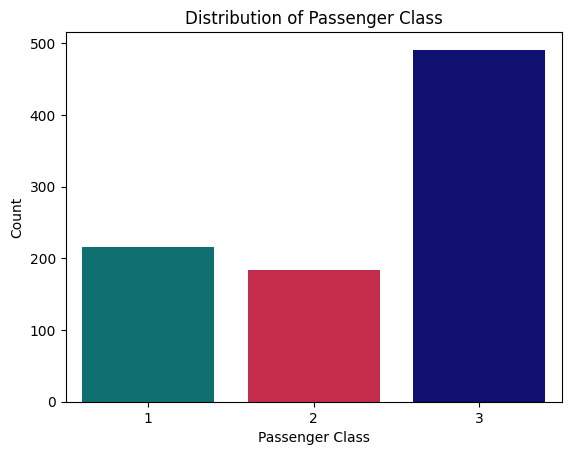

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Pclass", data=df, palette=["teal", "crimson", "navy"])
plt.title("Distribution of Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

Identify which class had the most passengers

In [13]:
df['Pclass'].value_counts()

,count
Pclass,
3,491
1,216
2,184


Class 3 had the most passangers

Plot a histogram of the Age column to visualize its distribution

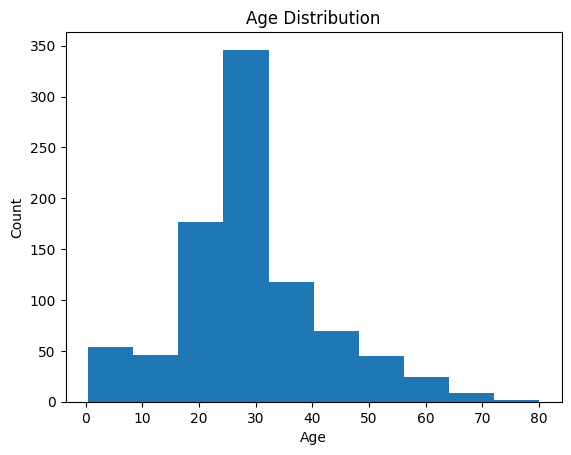

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.hist(df['Age'], bins=10)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

#Task 4: Bivariate and Multivariate Analysis

Calculate and visualize the survival rate for each Pclass

In [15]:
df[['Pclass', 'Survived']].groupby(['Pclass'],as_index=False).mean().sort_values(by='Survived',ascending=False)

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


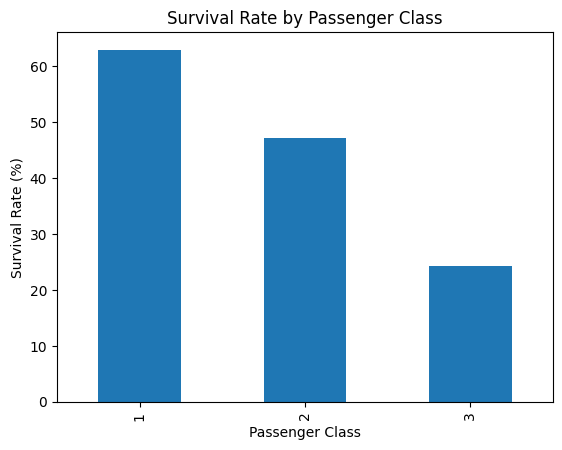

In [16]:
df.groupby('Pclass')['Survived'].mean().mul(100).plot(kind='bar')

plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.title('Survival Rate by Passenger Class')
plt.show()

There is a clear relationship between passenger class and survival rate. Passengers from higher class (especially 1st class) had a higher chance of survival compared to lower classes. This indicates the difference between socio-ecomic classes where the higher class always gets more priority. Also here the number of passengers from 3rd class is also higher which indicates their lower survival rate.

Plot and compare the age distribution of survivors vs. non-survivors

In [17]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 13, 30, 50, 100],
    labels=["Child", "Young", "Adult", "Senior"],
    right=False  # makes intervals: [0-13), [13-30), etc.
)
df[["AgeGroup", "Survived"]].groupby(["AgeGroup"], as_index=False).mean().sort_values(by="Survived", ascending=False)



/tmp/ipykernel_5640/1811967684.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df[["AgeGroup", "Survived"]].groupby(["AgeGroup"], as_index=False).mean().sort_values(by="Survived", ascending=False)


,AgeGroup,Survived
0,Child,0.579710
2,Adult,0.417969
3,Senior,0.364865
1,Young,0.341463


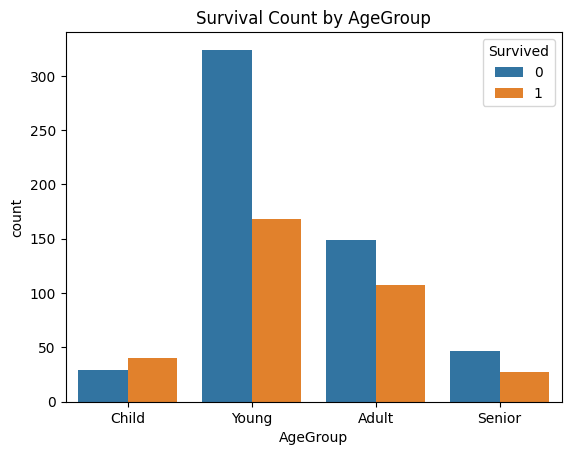

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='AgeGroup', hue='Survived', data=df)
plt.title('Survival Count by AgeGroup')
plt.show()

The number of children and elderly are lower than the number of young and adult. The polt suggests that the children had a relatively better chance of survival. Elderly passesngers appreared to had lower survival rates compared to younger adults.

Calculate and visualize the survival rate for each Embarked port

In [19]:
df[["Embarked", "Survived"]].groupby(["Embarked"], as_index=False).mean().sort_values(by="Survived", ascending=False)

,Embarked,Survived
0,C,0.553571
1,Q,0.389610
2,S,0.339009


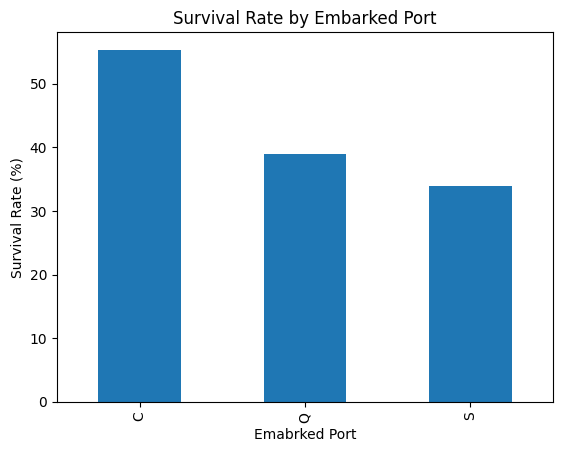

In [20]:
df.groupby('Embarked')['Survived'].mean().mul(100).plot(kind='bar')

plt.xlabel('Emabrked Port')
plt.ylabel('Survival Rate (%)')
plt.title('Survival Rate by Embarked Port')
plt.show()

#Task 5: Conclusion and Insights

Based on the exploratory data analysis, passenger class, age, and port of embarkation were among the most important factors affecting survival on the Titanic. Passengers traveling in 1st class had a significantly higher survival rate compared to those in lower classes, showing a strong relationship between socioeconomic status and survival probability. The analysis also suggested that children had better chances of survival than many adults and elderly passengers. Additionally, survival rates varied across embarkation ports, likely because different ports had different proportions of passenger classes. Overall, Pclass, Age, and Embarked appeared to be the strongest predictors of survival.